# Option Chain Analyzer - ETH + BTC

Live from Deribit API. No DB, no files, no API key.

Produces at the end:

- **ONE buy recommendation**
- **ONE sell recommendation**

Based on live option chain, Greeks, and IV.

## Setup

In [8]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from datetime import datetime, timezone
import time

pd.set_option('display.width', 180)
plt.rcParams['figure.figsize'] = (12, 4)

## 1. Fetch live chains from Deribit

In [9]:
DERIBIT = 'https://www.deribit.com/api/v2/public/get_book_summary_by_currency'

def fetch_chain(currency):
    r = requests.get(DERIBIT, params={'currency': currency, 'kind': 'option'}, timeout=30)
    r.raise_for_status()
    return r.json()['result']

In [10]:
def parse_name(name):
    parts = name.split('-')
    if len(parts) != 4:
        return None
    try:
        _, exp, strike, kind = parts
        dt = datetime.strptime(exp, '%d%b%y').replace(tzinfo=timezone.utc, hour=8)
        return int(dt.timestamp() * 1000), float(strike), kind
    except (ValueError, IndexError):
        return None

In [11]:
frames = []
for cur in ['ETH', 'BTC']:
    print(f'fetching {cur}...')
    raw = fetch_chain(cur)
    now_ms = int(time.time() * 1000)
    rows = []
    for r in raw:
        p = parse_name(r['instrument_name'])
        if p is None:
            continue
        rows.append({
            'underlying': cur, 'expiry': p[0], 'strike': p[1], 'kind': p[2],
            'ts': now_ms, 'mark_price': r.get('mark_price'),
            'bid': r.get('bid_price'), 'ask': r.get('ask_price'),
            'iv': r.get('mark_iv'), 'oi': r.get('open_interest'),
            'volume': r.get('volume'),
        })
    df_cur = pd.DataFrame(rows)
    print(f'  {len(df_cur)} instruments')
    frames.append(df_cur)
    time.sleep(0.5)

df = pd.concat(frames, ignore_index=True)
df['iv_dec'] = df['iv'] / 100.0
df['days'] = (df['expiry'] - df['ts']) / 86_400_000
print()
print(f'total: {len(df)} rows')
df.head()

fetching ETH...
  774 instruments
fetching BTC...
  922 instruments

total: 1696 rows


,underlying,expiry,strike,kind,ts,mark_price,bid,ask,iv,oi,volume,iv_dec,days
0,ETH,1792915200000,2340.0,P,1792839283505,0.003176,0.0030,0.0034,37.44,817.0,950.0,0.3744,0.878663
1,ETH,1795766400000,3100.0,P,1792839283505,0.310518,0.3065,0.3150,52.85,19.0,0.0,0.5285,33.878663
2,ETH,1821772800000,2300.0,P,1792839283505,0.163865,0.1625,0.1655,53.75,145.0,0.0,0.5375,334.878663
3,ETH,1794556800000,2200.0,P,1792839283505,0.020390,0.0200,0.0210,53.32,609.0,75.0,0.5332,19.878663
4,ETH,1813910400000,2900.0,P,1792839283505,0.296479,0.2945,0.2990,52.93,508.0,0.0,0.5293,243.878663


## 2. Estimate spot price

In [12]:
spots = {}
for cur in df.underlying.unique():
    sub = df[df.underlying == cur]
    near = sub[sub.expiry == sub.expiry.min()]
    spots[cur] = float(near.strike.median())

for k, v in spots.items():
    print(f'{k} spot ~ {v:.2f}')

ETH spot ~ 2480.00
BTC spot ~ 83750.00


## 3. Put/Call ratio

In [13]:
for cur in df.underlying.unique():
    s = df[df.underlying == cur]
    oic, oip = s[s.kind == 'C'].oi.sum(), s[s.kind == 'P'].oi.sum()
    vc, vp = s[s.kind == 'C'].volume.sum(), s[s.kind == 'P'].volume.sum()
    print(f'{cur}:  PCR(OI)={oip/max(oic,1):.2f}  PCR(vol)={vp/max(vc,1):.2f}')

ETH:  PCR(OI)=0.49  PCR(vol)=0.64
BTC:  PCR(OI)=0.59  PCR(vol)=0.77


## 4. IV smile

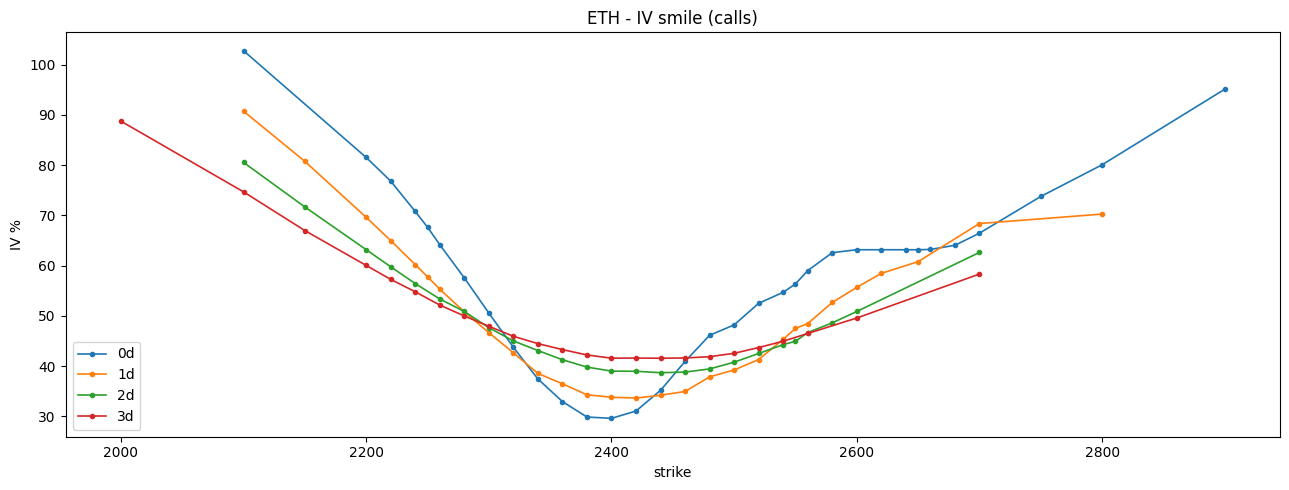

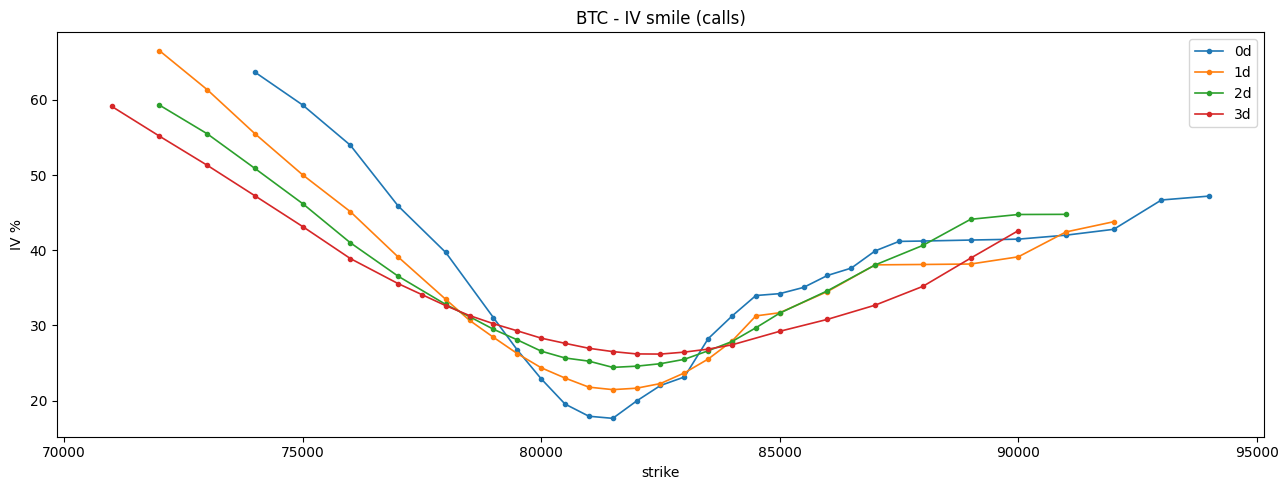

In [14]:
for cur in df.underlying.unique():
    sub = df[df.underlying == cur]
    exps = sorted(sub.expiry.unique())[:4]
    plt.figure(figsize=(13, 5))
    for e in exps:
        s = sub[(sub.expiry == e) & (sub.kind == 'C') & sub.iv_dec.notna()].sort_values('strike')
        if len(s):
            plt.plot(s.strike, s.iv_dec * 100, marker='o', ms=3, lw=1.2,
                     label=f'{int(s.days.iloc[0])}d')
    plt.title(f'{cur} - IV smile (calls)')
    plt.xlabel('strike'); plt.ylabel('IV %'); plt.legend()
    plt.tight_layout(); plt.show()

## 5. ATM IV term structure

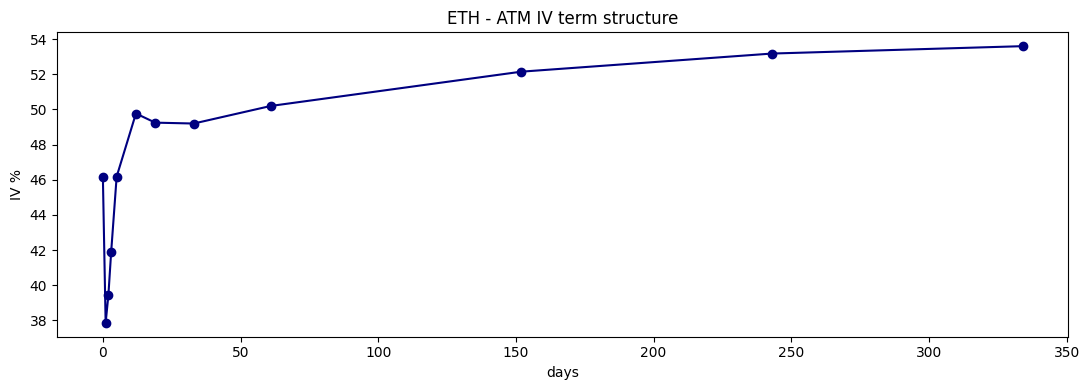

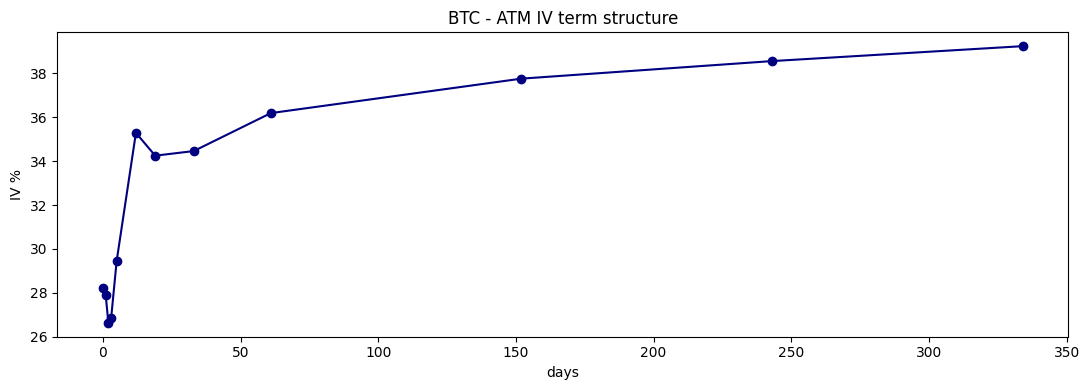

In [15]:
term = {}
for cur in df.underlying.unique():
    sub = df[df.underlying == cur]
    spot = spots[cur]
    rows = []
    for e, g in sub.groupby('expiry'):
        atm = g.iloc[(g.strike - spot).abs().argsort()[:1]]
        if len(atm) and pd.notna(atm.iv_dec.iloc[0]):
            rows.append({'days': int(atm.days.iloc[0]),
                         'atm_iv': float(atm.iv_dec.iloc[0]) * 100})
    ts = pd.DataFrame(rows).sort_values('days')
    term[cur] = ts
    plt.figure(figsize=(11, 4))
    plt.plot(ts.days, ts.atm_iv, marker='o', color='navy')
    plt.title(f'{cur} - ATM IV term structure')
    plt.xlabel('days'); plt.ylabel('IV %')
    plt.tight_layout(); plt.show()

## 6. Black-Scholes Greeks

In [16]:
def bs_greeks(S, K, T, sigma, kind):
    if T <= 0 or sigma <= 0:
        return None
    d1 = (np.log(S/K) + 0.5*sigma**2 * T) / (sigma * np.sqrt(T))
    pdf = norm.pdf(d1)
    delta = norm.cdf(d1) if kind == 'C' else norm.cdf(d1) - 1
    return {
        'delta': float(delta),
        'gamma': float(pdf / (S * sigma * np.sqrt(T))),
        'vega':  float(S * pdf * np.sqrt(T) / 100),
        'theta': float(-(S * pdf * sigma) / (2 * np.sqrt(T)) / 365),
    }

In [17]:
enriched = []
for cur in df.underlying.unique():
    sub = df[(df.underlying == cur) & df.iv_dec.notna() & df.days.between(1, 90)]
    for _, r in sub.iterrows():
        g = bs_greeks(spots[cur], r.strike, r.days/365, r.iv_dec, r.kind)
        if g:
            enriched.append({**r.to_dict(), **g})

ek = pd.DataFrame(enriched)
print(f'enriched: {len(ek)} contracts with Greeks')
ek.head()

enriched: 1026 contracts with Greeks


,underlying,expiry,strike,kind,ts,mark_price,bid,ask,iv,oi,volume,iv_dec,days,delta,gamma,vega,theta
0,ETH,1795766400000,3100.0,P,1792839283505,0.310518,0.3065,0.3150,52.85,19.0,0.0,0.5285,33.878663,-0.904116,0.000426,1.285775,-1.002891
1,ETH,1794556800000,2200.0,P,1792839283505,0.020390,0.0200,0.0210,53.32,609.0,75.0,0.5332,19.878663,-0.152684,0.000765,1.365442,-1.831244
2,ETH,1793347200000,2150.0,C,1792839283505,0.095747,0.0940,0.0975,63.21,988.0,0.0,0.6321,5.878663,0.965629,0.000383,0.239599,-1.288138
3,ETH,1793174400000,2320.0,P,1792839283505,0.010592,0.0100,0.0110,45.94,0.0,0.0,0.4594,3.878663,-0.076080,0.001218,0.365851,-2.166624
4,ETH,1793952000000,3000.0,C,1792839283505,0.000992,0.0009,0.0011,61.77,2021.0,183.0,0.6177,12.878663,0.056761,0.000396,0.531263,-1.274049


## 7. Open interest by strike

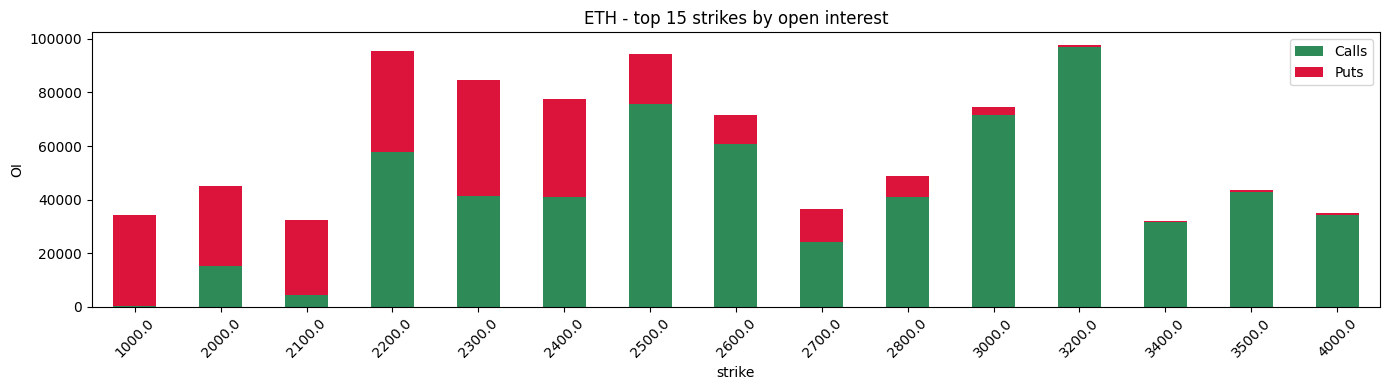

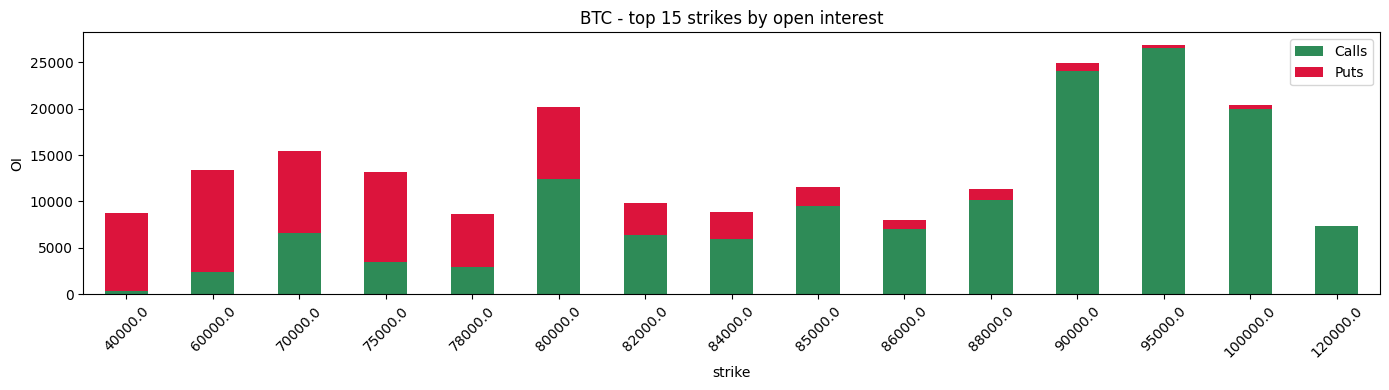

In [18]:
for cur in df.underlying.unique():
    s = df[df.underlying == cur]
    oi = s.pivot_table(index='strike', columns='kind',
                        values='oi', aggfunc='sum').fillna(0)
    oi['total'] = oi.sum(axis=1)
    top = oi.nlargest(15, 'total').sort_index()
    plt.figure(figsize=(14, 4))
    top[['C','P']].plot(kind='bar', stacked=True, ax=plt.gca(),
                        color=['seagreen','crimson'])
    plt.title(f'{cur} - top 15 strikes by open interest')
    plt.xlabel('strike'); plt.ylabel('OI')
    plt.xticks(rotation=45)
    plt.legend(['Calls','Puts'])
    plt.tight_layout(); plt.show()

## 8. IV rank per expiry

Compare current ATM IV to the min/max IV across strikes for that expiry. High = vol rich, low = vol cheap.

In [19]:
iv_rank = []
for cur in df.underlying.unique():
    sub = df[(df.underlying == cur) & df.iv_dec.notna()]
    for e, g in sub.groupby('expiry'):
        lo, hi = g.iv_dec.min(), g.iv_dec.max()
        atm = g.iloc[(g.strike - spots[cur]).abs().argsort()[:1]]
        if len(atm) and hi > lo:
            rank = (atm.iv_dec.iloc[0] - lo) / (hi - lo)
            iv_rank.append({
                'underlying': cur, 'days': int(atm.days.iloc[0]),
                'atm_iv': float(atm.iv_dec.iloc[0]) * 100,
                'iv_rank': float(rank),
            })

ivr = pd.DataFrame(iv_rank).sort_values(['underlying','days'])
ivr

,underlying,days,atm_iv,iv_rank
12,BTC,0,28.24,0.230135
13,BTC,1,27.92,0.143269
14,BTC,2,26.63,0.063342
15,BTC,3,26.85,0.020030
16,BTC,5,29.45,0.005675
17,BTC,12,35.29,0.006016
18,BTC,19,34.25,0.030025
19,BTC,33,34.46,0.030839
20,BTC,61,36.19,0.010455
21,BTC,152,37.76,0.018328


## 9. Skew (25-delta put vs 25-delta call)

Negative skew = puts more expensive = fear. Positive skew = calls more expensive = greed.

In [20]:
def skew_25d(currency):
    sub = ek[ek.underlying == currency].copy()
    if sub.empty:
        return None
    near = sub[sub.days.between(15, 45)]
    if near.empty:
        near = sub
    calls = near[near.kind == 'C'].sort_values('delta')
    puts  = near[near.kind == 'P'].sort_values('delta')
    if calls.empty or puts.empty:
        return None
    c25 = calls.iloc[(calls.delta - 0.25).abs().argsort()[:1]]
    p25 = puts.iloc[(puts.delta + 0.25).abs().argsort()[:1]]
    return float(p25.iv_dec.iloc[0] - c25.iv_dec.iloc[0])

for cur in ek.underlying.unique():
    s = skew_25d(cur)
    if s is not None:
        print(f'{cur} 25d skew = {s*100:+.2f}% IV  '
              f"({'fear' if s>0 else 'greed'})")

ETH 25d skew = +1.33% IV  (fear)
BTC 25d skew = +3.13% IV  (fear)


## 10. Candidate contracts for BUY and SELL

Filter to liquid, near-term options (7-45 days).

In [21]:
def liquid_candidates(currency, kind):
    s = ek[(ek.underlying == currency)
           & (ek.kind == kind)
           & ek.days.between(7, 45)
           & (ek.oi > 0)
           & (ek.volume > 0)
           & (ek.bid > 0) & (ek.ask > 0)].copy()
    s['spread_pct'] = (s.ask - s.bid) / ((s.ask + s.bid) / 2)
    return s[s.spread_pct < 0.15]

for cur in ek.underlying.unique():
    for kind in ['C','P']:
        c = liquid_candidates(cur, kind)
        print(f'{cur} {kind}: {len(c)} liquid contracts')

ETH C: 40 liquid contracts
ETH P: 25 liquid contracts
BTC C: 46 liquid contracts
BTC P: 42 liquid contracts


## 11. BUY recommendation

Pick the contract with best risk/reward:
- Liquid (tight spread, real volume)
- Delta 0.30-0.60 (real directional exposure without ruin)
- Positive expected move based on IV rank

In [22]:
def pick_buy(currency):
    best = None
    for kind in ['C','P']:
        c = liquid_candidates(currency, kind)
        c = c[c.delta.between(0.30, 0.60) if kind=='C' else c.delta.between(-0.60, -0.30)]
        if c.empty:
            continue
        # score: low IV (cheap) + high OI (liquid) + tight spread
        c = c.copy()
        c['score'] = (-c.iv_dec) + (c.oi / c.oi.max()) - c.spread_pct
        top = c.nlargest(1, 'score').iloc[0]
        if best is None or top.score > best.score:
            best = top
    return best

buys = {}
for cur in ek.underlying.unique():
    b = pick_buy(cur)
    if b is not None:
        buys[cur] = b

print('BUY candidates per underlying:')
for cur, b in buys.items():
    print(f"\n{cur}:")
    print(f"  {cur}-{datetime.utcfromtimestamp(b.expiry/1000):%d%b%y}-{int(b.strike)}-{b.kind}")
    print(f"  bid/ask: {b.bid:.4f} / {b.ask:.4f}   mark: {b.mark_price:.4f}")
    print(f"  IV: {b.iv_dec*100:.2f}%   delta: {b.delta:.3f}   gamma: {b.gamma:.5f}")
    print(f"  vega: {b.vega:.4f}   theta: {b.theta:.4f}")
    print(f"  OI: {b.oi:.0f}   vol: {b.volume:.0f}   spread: {b.spread_pct*100:.2f}%")

BUY candidates per underlying:

ETH:
  ETH-27Nov26-2500-C
  bid/ask: 0.0375 / 0.0385   mark: 0.0381
  IV: 49.20%   delta: 0.509   gamma: 0.00107
  vega: 3.0136   theta: -2.1882
  OI: 5049   vol: 2024   spread: 2.63%

BTC:
  BTC-27Nov26-80000-P
  bid/ask: 0.0375 / 0.0385   mark: 0.0381
  IV: 36.11%   delta: -0.319   gamma: 0.00004
  vega: 91.0869   theta: -48.5431
  OI: 856   vol: 153   spread: 2.63%


## 12. SELL recommendation

The highest-IV contract among liquid candidates, restricted to OTM (delta < 0.30 absolute). This is the option most overpriced relative to the rest of the chain.

In [23]:
def pick_sell(currency):
    best = None
    for kind in ['C','P']:
        c = liquid_candidates(currency, kind)
        if kind == 'C':
            c = c[c.delta < 0.30]
        else:
            c = c[c.delta > -0.30]
        if c.empty:
            continue
        top = c.nlargest(1, 'iv_dec').iloc[0]
        if best is None or top.iv_dec > best.iv_dec:
            best = top
    return best

sells = {}
for cur in ek.underlying.unique():
    s = pick_sell(cur)
    if s is not None:
        sells[cur] = s

print('SELL candidates per underlying:')
for cur, s in sells.items():
    print(f"\n{cur}:")
    print(f"  {cur}-{datetime.utcfromtimestamp(s.expiry/1000):%d%b%y}-{int(s.strike)}-{s.kind}")
    print(f"  bid/ask: {s.bid:.4f} / {s.ask:.4f}   mark: {s.mark_price:.4f}")
    print(f"  IV: {s.iv_dec*100:.2f}%   delta: {s.delta:.3f}   gamma: {s.gamma:.5f}")
    print(f"  vega: {s.vega:.4f}   theta: {s.theta:.4f}")
    print(f"  OI: {s.oi:.0f}   vol: {s.volume:.0f}   spread: {s.spread_pct*100:.2f}%")

print()
print('=' * 70)
print('FINAL: ONE BUY + ONE SELL')
print('=' * 70)

if 'ETH' in buys and 'ETH' in sells:
    b, s = buys['ETH'], sells['ETH']
    print()
    print(f'BUY  : {int(b.strike)} {b.kind}  exp {datetime.utcfromtimestamp(b.expiry/1000):%Y-%m-%d}  '
          f'@ {b.ask:.2f}  IV {b.iv_dec*100:.1f}%  delta {b.delta:.2f}')
    print(f'SELL : {int(s.strike)} {s.kind}  exp {datetime.utcfromtimestamp(s.expiry/1000):%Y-%m-%d}  '
          f'@ {s.bid:.2f}  IV {s.iv_dec*100:.1f}%  delta {s.delta:.2f}')
else:
    print('no candidates found - rerun later')

SELL candidates per underlying:

ETH:
  ETH-13Nov26-1800-P
  bid/ask: 0.0028 / 0.0031   mark: 0.0030
  IV: 71.17%   delta: -0.022   gamma: 0.00013
  vega: 0.3047   theta: -0.5455
  OI: 115   vol: 1   spread: 10.17%

BTC:
  BTC-27Nov26-60000-P
  bid/ask: 0.0020 / 0.0023   mark: 0.0021
  IV: 54.83%   delta: -0.019   gamma: 0.00000
  vega: 11.7032   theta: -9.4704
  OI: 266   vol: 2   spread: 13.95%

FINAL: ONE BUY + ONE SELL

BUY  : 2500 C  exp 2026-11-27  @ 0.04  IV 49.2%  delta 0.51
SELL : 1800 P  exp 2026-11-13  @ 0.00  IV 71.2%  delta -0.02
